# Threat Analysis and Risk Assessment (TARA)

**Module 05 · Cybersecurity (ISO/SAE 21434)** · Notebook 2 of 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/05_Cybersecurity_ISO21434/02_tara.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~80 min | [ISO/SAE 21434 fundamentals](01_iso21434_fundamentals.ipynb), [HARA](../03_Functional_Safety_ISO26262/02_hara.ipynb) | ISO/SAE 21434:2021 (cl. 9, 15; Annexes E–H), ISO 26262-3:2018 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:
- perform all seven TARA steps of ISO/SAE 21434 clause 15 for a perception-based AEB function, in the order of the standard;
- formulate threat scenarios as *asset + cybersecurity property + cause* and link them to damage scenarios;
- build attack paths, aggregate them (AND/OR) and rate attack feasibility with the attack-potential approach;
- derive risk values, treatment decisions, cybersecurity goals/claims and CALs **programmatically**, so that every number is traceable;
- connect the TARA to the HARA of Module 03 (safety–security co-engineering), including timing of security controls against the FTTI.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 160)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
rng = np.random.default_rng(42)
print('Setup complete.')

Setup complete.


## 1. Introduction to TARA

**TARA (Threat Analysis and Risk Assessment)** is the cybersecurity counterpart of the HARA in ISO 26262.
The two are analogous, not equivalent: a TARA considers *deliberate* attacks and rates their *feasibility*;
a HARA considers *malfunctions* and rates exposure and controllability.

TARA methods are defined in **clause 15** and used in the concept phase (clause 9), during product development (clause 10)
and whenever new information arrives (clause 8, e.g. a newly published vulnerability). The steps, in the standard's order:

1. **Asset identification and damage scenarios** (15.3)
2. **Threat scenario identification** (15.4)
3. **Impact rating** (15.5)
4. **Attack path analysis** (15.6)
5. **Attack feasibility rating** (15.7)
6. **Risk value determination** (15.8)
7. **Risk treatment decision** (15.9) → cybersecurity goals (clause 9.4) or cybersecurity claims

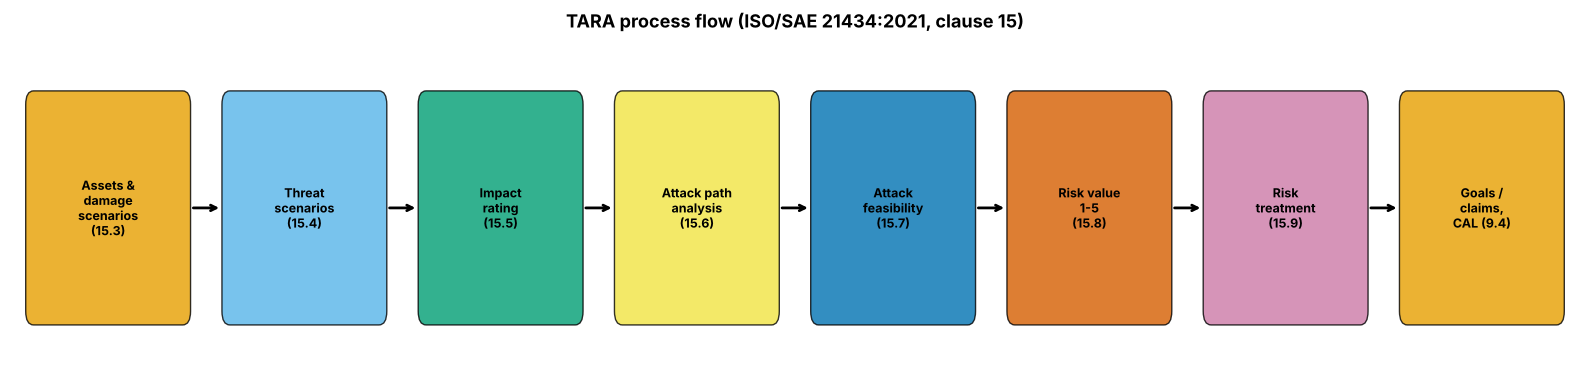

--- TARA steps (text summary) ---
  1. Assets & damage scenarios (15.3)
  2. Threat scenarios (15.4)
  3. Impact rating (15.5)
  4. Attack path analysis (15.6)
  5. Attack feasibility (15.7)
  6. Risk value 1-5 (15.8)
  7. Risk treatment (15.9)
  8. Goals / claims, CAL (9.4)


In [2]:
def visualize_tara_process():
    """TARA process flow in the order of ISO/SAE 21434 clause 15."""
    steps = ['Assets &\ndamage\nscenarios\n(15.3)', 'Threat\nscenarios\n(15.4)', 'Impact\nrating\n(15.5)',
             'Attack path\nanalysis\n(15.6)', 'Attack\nfeasibility\n(15.7)', 'Risk value\n1-5\n(15.8)',
             'Risk\ntreatment\n(15.9)', 'Goals /\nclaims,\nCAL (9.4)']
    fig, ax = plt.subplots(figsize=(16, 4))
    xs = np.linspace(0.5, 7.5, len(steps))
    colours = [OKABE_ITO[i % 7] for i in range(len(steps))]
    for i, (label, x) in enumerate(zip(steps, xs)):
        ax.add_patch(FancyBboxPatch((x - 0.38, 0.2), 0.76, 0.6, boxstyle='round,pad=0.04',
                                    facecolor=colours[i], edgecolor='black', alpha=0.8))
        ax.text(x, 0.5, label, ha='center', va='center', fontsize=9, fontweight='bold')
        if i < len(steps) - 1:
            ax.annotate('', xy=(xs[i + 1] - 0.42, 0.5), xytext=(x + 0.42, 0.5), arrowprops=dict(arrowstyle='->', lw=2))
    ax.set_xlim(0, 8); ax.set_ylim(0, 1); ax.axis('off')
    ax.set_title('TARA process flow (ISO/SAE 21434:2021, clause 15)', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()
    print('--- TARA steps (text summary) ---')
    for i, s in enumerate(steps, 1):
        print(f'  {i}. ' + s.replace(chr(10), ' '))

visualize_tara_process()

## 2. Item definition and the safety interface

ISO/SAE 21434 (cl. 9.3) and ISO 26262-3 (cl. 5) both start from an **item definition**. The two analyses should share one
item definition. Below, the item is the **pedestrian automatic emergency braking (AEB) function** of the perception chain studied in
Module 03 (HARA). The perception ECU fuses camera and radar detections and sends an object list / brake request to the brake ECU over CAN-FD.

The HARA's **safety goals** become inputs to the TARA: violating a safety goal is a *safety damage scenario*.
The S/E/C values below are an illustrative stand-in for the HARA in Module 03. The ASIL is computed with ISO 26262-3:2018 Table 4,
the same function as `avsafety.iso26262.determine_asil`.

> **Illustrative data:** item details, S/E/C classes and FTTI values are synthetic, chosen for teaching.

In [3]:
item = {
    'Item': 'Pedestrian AEB function (camera + radar perception -> brake request)',
    'Boundary (in)': ['Front camera', 'Front radar', 'Perception ECU (DNN detector, fusion, AEB logic)',
                      'Perception-ECU software, model weights, calibration data', 'CAN-FD link perception ECU -> brake ECU'],
    'Boundary (out, interfaces)': ['Brake ECU (actuation)', 'Central gateway (diagnostics, OTA client)',
                                   'Telematics unit (cellular)', 'OEM backend (OTA, event-clip upload)'],
    'Operating modes': ['Active', 'Degraded (driver warned, AEB unavailable)', 'Off / diagnostic session'],
}
for k, v in item.items():
    print(f'{k}:')
    for x in (v if isinstance(v, list) else [v]):
        print(f'  - {x}')

# ISO 26262-3:2018 Table 4 (same as avsafety.iso26262.ASIL_TABLE): ASIL_TABLE[S][E] -> (C1, C2, C3)
ASIL_TABLE = {
    'S1': {'E1': ('QM', 'QM', 'QM'), 'E2': ('QM', 'QM', 'QM'), 'E3': ('QM', 'QM', 'A'), 'E4': ('QM', 'A', 'B')},
    'S2': {'E1': ('QM', 'QM', 'QM'), 'E2': ('QM', 'QM', 'A'), 'E3': ('QM', 'A', 'B'), 'E4': ('A', 'B', 'C')},
    'S3': {'E1': ('QM', 'QM', 'A'), 'E2': ('QM', 'A', 'B'), 'E3': ('A', 'B', 'C'), 'E4': ('B', 'C', 'D')},
}
def determine_asil(s, e, c):
    if 'S0' in s or 'E0' in e or 'C0' in c:
        return 'QM'
    return ASIL_TABLE[s][e][int(c[1]) - 1]

safety_goals = pd.DataFrame([
    ('SG-01', 'Avoid unintended emergency braking', 'S2', 'E4', 'C2', 200),
    ('SG-02', 'Avoid omission of emergency braking for a pedestrian in the path', 'S3', 'E3', 'C3', 300),
], columns=['SG', 'Safety goal', 'S', 'E', 'C', 'FTTI_ms'])
safety_goals['ASIL'] = [determine_asil(r.S, r.E, r.C) for r in safety_goals.itertuples()]
print()
display(safety_goals)
print('--- Safety goals (text summary) ---')
for r in safety_goals.to_dict('records'):
    print(f"  {r['SG']}: {r['Safety goal']} | {r['S']}/{r['E']}/{r['C']} -> ASIL {r['ASIL']} | FTTI {r['FTTI_ms']} ms (illustrative)")

Item:
  - Pedestrian AEB function (camera + radar perception -> brake request)
Boundary (in):
  - Front camera
  - Front radar
  - Perception ECU (DNN detector, fusion, AEB logic)
  - Perception-ECU software, model weights, calibration data
  - CAN-FD link perception ECU -> brake ECU
Boundary (out, interfaces):
  - Brake ECU (actuation)
  - Central gateway (diagnostics, OTA client)
  - Telematics unit (cellular)
  - OEM backend (OTA, event-clip upload)
Operating modes:
  - Active
  - Degraded (driver warned, AEB unavailable)
  - Off / diagnostic session



,SG,Safety goal,S,E,C,FTTI_ms,ASIL
0,SG-01,Avoid unintended emergency braking,S2,E4,C2,200,B
1,SG-02,Avoid omission of emergency braking for a pedestrian in the path,S3,E3,C3,300,C


--- Safety goals (text summary) ---
  SG-01: Avoid unintended emergency braking | S2/E4/C2 -> ASIL B | FTTI 200 ms (illustrative)
  SG-02: Avoid omission of emergency braking for a pedestrian in the path | S3/E3/C3 -> ASIL C | FTTI 300 ms (illustrative)


## 3. Rating tables

The tables are the informative examples of ISO/SAE 21434 (Annex G attack potential, Annex H risk matrix, Annex E CAL),
exactly as introduced in [Notebook 1](01_iso21434_fundamentals.ipynb). They are identical to `avsafety.iso21434` in this repository.

**Attack path aggregation.** The standard asks for attack paths but does not prescribe how to combine the steps.
This notebook uses one common, conservative convention:
- **AND** (all steps of one path are needed): for each factor, take the **maximum** over the steps. The attacker must master the hardest step on every dimension. Taking the maximum elapsed time *underestimates* the total time of sequential steps, so it is a feasibility-conservative simplification.
- **OR** (alternative paths): the threat scenario is as feasible as its **most feasible** path, i.e. the path with the minimum attack potential.

Document whichever convention you choose in the TARA method description.

In [4]:
IMPACT_LEVELS = ['Negligible', 'Moderate', 'Major', 'Severe']
FEASIBILITY_LEVELS = ['Very Low', 'Low', 'Medium', 'High']
FACTORS = {
    'elapsed_time': {'<=1 day': 0, '<=1 week': 1, '<=1 month': 4, '<=6 months': 17, '>6 months': 19},
    'expertise':    {'layman': 0, 'proficient': 3, 'expert': 6, 'multiple experts': 8},
    'knowledge':    {'public': 0, 'restricted': 3, 'confidential': 7, 'strictly confidential': 11},
    'window':       {'unlimited': 0, 'easy': 1, 'moderate': 4, 'difficult': 10},
    'equipment':    {'standard': 0, 'specialized': 4, 'bespoke': 7, 'multiple bespoke': 9},
}
VECTORS = ['Physical', 'Local', 'Adjacent', 'Network']        # ordered from least to most remote
FEASIBILITY_FROM_VECTOR = {'Network': 'High', 'Adjacent': 'Medium', 'Local': 'Low', 'Physical': 'Very Low'}
RISK_MATRIX = {
    'Severe':     {'Very Low': 2, 'Low': 3, 'Medium': 4, 'High': 5},
    'Major':      {'Very Low': 1, 'Low': 2, 'Medium': 3, 'High': 4},
    'Moderate':   {'Very Low': 1, 'Low': 2, 'Medium': 2, 'High': 3},
    'Negligible': {'Very Low': 1, 'Low': 1, 'Medium': 1, 'High': 1},
}
CAL_TABLE = {
    'Severe':   {'Physical': 2, 'Local': 3, 'Adjacent': 4, 'Network': 4},
    'Major':    {'Physical': 1, 'Local': 2, 'Adjacent': 3, 'Network': 4},
    'Moderate': {'Physical': 1, 'Local': 1, 'Adjacent': 2, 'Network': 3},
}

def feasibility_from_potential(ap):
    return 'High' if ap <= 13 else 'Medium' if ap <= 19 else 'Low' if ap <= 24 else 'Very Low'

def determine_cal(impact, vector):
    return None if impact == 'Negligible' else CAL_TABLE[impact][vector]

def step(action, elapsed_time, expertise, knowledge, window, equipment, vector=None):
    """One attack step; factor values are validated against the Annex G tables."""
    s = {'action': action, 'vector': vector}
    for name, label in zip(FACTORS, (elapsed_time, expertise, knowledge, window, equipment)):
        if label not in FACTORS[name]:
            raise ValueError(f'invalid {name}: {label!r}')
        s[name] = FACTORS[name][label]
    return s

def aggregate_and(steps, floors=None):
    """AND aggregation: factor-wise maximum over steps (optionally raised to control 'floors')."""
    agg = {f: max(s[f] for s in steps) for f in FACTORS}
    for f, label in (floors or {}).items():
        agg[f] = max(agg[f], FACTORS[f][label])
    agg['attack_potential'] = sum(agg[f] for f in FACTORS)
    agg['feasibility'] = feasibility_from_potential(agg['attack_potential'])
    agg['vector'] = steps[0]['vector']  # the entry point determines the attack vector
    return agg

assert feasibility_from_potential(13) == 'High' and feasibility_from_potential(25) == 'Very Low'
assert determine_cal('Severe', 'Network') == 4 and determine_cal('Negligible', 'Network') is None
print('Rating tables and aggregation helpers ready.')

Rating tables and aggregation helpers ready.


## 4. Step 1 — Assets and damage scenarios (15.3)

An **asset** is an object that has value, and whose compromise of one or more **cybersecurity properties**
(confidentiality, integrity, availability; organisations often add authenticity, authorisation, non-repudiation) can lead to a damage scenario.
A **damage scenario** describes the adverse consequence for a road user. It is rated later in the SFOP categories.

| Category | Examples |
|---|---|
| Data | Sensor streams, object list, calibration parameters, recorded clips |
| Software | DNN weights, firmware |
| Communication | CAN-FD messages, V2X, OTA channel |
| Function | Pedestrian detection, brake request |

Safety damage scenarios correspond to violations of the HARA safety goals, so the link to SG-01/SG-02 is recorded explicitly.

In [5]:
assets = pd.DataFrame([
    ('A-01', 'Camera video stream (camera -> perception ECU)', 'Data', ['Integrity', 'Availability']),
    ('A-02', 'Perception DNN weights and configuration', 'Software', ['Integrity']),
    ('A-03', 'Object list / brake request on CAN-FD', 'Communication', ['Integrity', 'Availability']),
    ('A-04', 'Perception-ECU firmware', 'Software', ['Integrity']),
    ('A-05', 'Camera calibration parameters (extrinsics)', 'Data', ['Integrity']),
    ('A-06', 'Recorded AEB event clips (camera images)', 'Data', ['Confidentiality']),
], columns=['Asset', 'Name', 'Category', 'Properties'])

# Damage scenarios: impact per SFOP category from the road user's perspective (0..3 = Negligible..Severe)
damage = pd.DataFrame([
    ('DS-01', 'Unintended emergency braking in following traffic leads to a rear-end collision', 2, 1, 1, 0, 'SG-01'),
    ('DS-02', 'No or late emergency braking for a pedestrian in the path leads to a fatal collision', 3, 2, 2, 0, 'SG-02'),
    ('DS-03', 'AEB unavailable (degraded mode, driver warned)', 0, 0, 2, 0, '-'),
    ('DS-04', 'Recorded images of identifiable pedestrians/occupants are disclosed', 0, 1, 0, 2, '-'),
], columns=['DS', 'Damage scenario', 'Safety', 'Financial', 'Operational', 'Privacy', 'Safety goal'])
for c in ['Safety', 'Financial', 'Operational', 'Privacy']:
    damage[c + '_label'] = damage[c].map(lambda v: IMPACT_LEVELS[v])
damage['Impact'] = damage[['Safety', 'Financial', 'Operational', 'Privacy']].max(axis=1).map(lambda v: IMPACT_LEVELS[v])

display(assets)
display(damage[['DS', 'Damage scenario', 'Safety_label', 'Financial_label', 'Operational_label', 'Privacy_label', 'Impact', 'Safety goal']])
print('--- Damage scenarios (text summary) ---')
for r in damage.to_dict('records'):
    print(f"  {r['DS']}: {r['Damage scenario']} | impact {r['Impact']}" + (f" | violates {r['Safety goal']}" if r['Safety goal'] != '-' else ''))

,Asset,Name,Category,Properties
0,A-01,Camera video stream (camera -> perception ECU),Data,"[Integrity, Availability]"
1,A-02,Perception DNN weights and configuration,Software,[Integrity]
2,A-03,Object list / brake request on CAN-FD,Communication,"[Integrity, Availability]"
3,A-04,Perception-ECU firmware,Software,[Integrity]
4,A-05,Camera calibration parameters (extrinsics),Data,[Integrity]
5,A-06,Recorded AEB event clips (camera images),Data,[Confidentiality]


,DS,Damage scenario,Safety_label,Financial_label,Operational_label,Privacy_label,Impact,Safety goal
0,DS-01,Unintended emergency braking in following traffic leads to a rear-end collision,Major,Moderate,Moderate,Negligible,Major,SG-01
1,DS-02,No or late emergency braking for a pedestrian in the path leads to a fatal c...,Severe,Major,Major,Negligible,Severe,SG-02
2,DS-03,"AEB unavailable (degraded mode, driver warned)",Negligible,Negligible,Major,Negligible,Major,-
3,DS-04,Recorded images of identifiable pedestrians/occupants are disclosed,Negligible,Moderate,Negligible,Major,Major,-


--- Damage scenarios (text summary) ---
  DS-01: Unintended emergency braking in following traffic leads to a rear-end collision | impact Major | violates SG-01
  DS-02: No or late emergency braking for a pedestrian in the path leads to a fatal collision | impact Severe | violates SG-02
  DS-03: AEB unavailable (degraded mode, driver warned) | impact Major
  DS-04: Recorded images of identifiable pedestrians/occupants are disclosed | impact Major


## 5. Step 2 — Threat scenarios (15.4)

A threat scenario names the **asset**, the compromised **cybersecurity property** and the **cause**, and links to one or more
damage scenarios. Example: *"Spoofing of object-list frames on CAN-FD leads to loss of integrity of the brake request, which can cause DS-01."*

STRIDE is a useful heuristic to brainstorm causes. Each STRIDE category threatens one property:
Spoofing → authenticity, Tampering → integrity, Repudiation → non-repudiation, Information disclosure → confidentiality,
Denial of service → availability, Elevation of privilege → authorisation.

**Boundary note.** TS-03 (adversarial patch) and TS-04 (dazzling) attack the *environment* in front of the sensor, not the data link.
They are cybersecurity threat scenarios because they are deliberate. The same perception weaknesses must also be analysed under
ISO 21448 (triggering conditions) and ISO/PAS 8800 (ML robustness); see [adversarial attacks](../02_Failures_and_Robustness/04_adversarial_attacks.ipynb).

In [6]:
STRIDE_PROPERTY = {'Spoofing': 'Integrity', 'Tampering': 'Integrity', 'Information disclosure': 'Confidentiality',
                   'Denial of service': 'Availability'}   # authenticity is treated as part of integrity here

threats = pd.DataFrame([
    ('TS-01', 'A-03', 'Spoofing', 'forged object-list/brake-request frames injected on CAN-FD', ['DS-01']),
    ('TS-02', 'A-02', 'Tampering', 'manipulated DNN weights installed through a malicious software update', ['DS-02']),
    ('TS-03', 'A-03', 'Tampering', 'a physical adversarial patch that suppresses pedestrian detections', ['DS-02']),
    ('TS-04', 'A-01', 'Denial of service', 'dazzling of the camera with a high-power light source', ['DS-02', 'DS-03']),
    ('TS-05', 'A-05', 'Tampering', 'calibration parameters rewritten via diagnostic services', ['DS-02']),
    ('TS-06', 'A-06', 'Information disclosure', 'event clips read out via diagnostic services', ['DS-04']),
    ('TS-07', 'A-03', 'Denial of service', 'flooding of the CAN-FD segment with high-priority frames', ['DS-03']),
], columns=['TS', 'Asset', 'STRIDE', 'Cause', 'Damage scenarios'])

asset_name = dict(zip(assets.Asset, assets.Name))
asset_props = dict(zip(assets.Asset, assets.Properties))
threats['Property'] = threats.STRIDE.map(STRIDE_PROPERTY)
# Consistency checks: the threatened property must be a property of the asset, and DS references must exist
for r in threats.to_dict('records'):
    assert r['Property'] in asset_props[r['Asset']], f"{r['TS']}: {r['Property']} not a property of {r['Asset']}"
    assert set(r['Damage scenarios']) <= set(damage.DS), f"{r['TS']}: unknown damage scenario"
threats['Threat scenario'] = [f'Loss of {r["Property"].lower()} of "{asset_name[r["Asset"]]}" caused by {r["Cause"]}'
                              for r in threats.to_dict('records')]
display(threats[['TS', 'Asset', 'STRIDE', 'Property', 'Threat scenario', 'Damage scenarios']])
print('--- Threat scenarios (text summary) ---')
for r in threats.to_dict('records'):
    print(f"  {r['TS']}: {r['Threat scenario']} -> {', '.join(r['Damage scenarios'])}")

,TS,Asset,STRIDE,Property,Threat scenario,Damage scenarios
0,TS-01,A-03,Spoofing,Integrity,"Loss of integrity of ""Object list / brake request on CAN-FD"" caused by forge...",[DS-01]
1,TS-02,A-02,Tampering,Integrity,"Loss of integrity of ""Perception DNN weights and configuration"" caused by ma...",[DS-02]
2,TS-03,A-03,Tampering,Integrity,"Loss of integrity of ""Object list / brake request on CAN-FD"" caused by a phy...",[DS-02]
3,TS-04,A-01,Denial of service,Availability,"Loss of availability of ""Camera video stream (camera -> perception ECU)"" cau...","[DS-02, DS-03]"
4,TS-05,A-05,Tampering,Integrity,"Loss of integrity of ""Camera calibration parameters (extrinsics)"" caused by ...",[DS-02]
5,TS-06,A-06,Information disclosure,Confidentiality,"Loss of confidentiality of ""Recorded AEB event clips (camera images)"" caused...",[DS-04]
6,TS-07,A-03,Denial of service,Availability,"Loss of availability of ""Object list / brake request on CAN-FD"" caused by fl...",[DS-03]


--- Threat scenarios (text summary) ---
  TS-01: Loss of integrity of "Object list / brake request on CAN-FD" caused by forged object-list/brake-request frames injected on CAN-FD -> DS-01
  TS-02: Loss of integrity of "Perception DNN weights and configuration" caused by manipulated DNN weights installed through a malicious software update -> DS-02
  TS-03: Loss of integrity of "Object list / brake request on CAN-FD" caused by a physical adversarial patch that suppresses pedestrian detections -> DS-02
  TS-04: Loss of availability of "Camera video stream (camera -> perception ECU)" caused by dazzling of the camera with a high-power light source -> DS-02, DS-03
  TS-05: Loss of integrity of "Camera calibration parameters (extrinsics)" caused by calibration parameters rewritten via diagnostic services -> DS-02
  TS-06: Loss of confidentiality of "Recorded AEB event clips (camera images)" caused by event clips read out via diagnostic services -> DS-04
  TS-07: Loss of availability of "Obje

## 6. Step 3 — Impact rating (15.5)

The impact of a threat scenario is the impact of its damage scenarios. With several linked damage scenarios we take the worst SFOP rating, which is conservative.
Impact is rated **before** considering the controls that the TARA will later define. The rating takes the road user's view.

In [7]:
ds_index = damage.set_index('DS')
def impact_of(ds_list):
    sfop = ds_index.loc[ds_list, ['Safety', 'Financial', 'Operational', 'Privacy']].max(axis=0)
    return IMPACT_LEVELS[int(sfop.max())], {k: IMPACT_LEVELS[int(v)] for k, v in sfop.items()}

threats['Impact'] = [impact_of(d)[0] for d in threats['Damage scenarios']]
threats['Safety impact'] = [impact_of(d)[1]['Safety'] for d in threats['Damage scenarios']]
display(threats[['TS', 'Damage scenarios', 'Safety impact', 'Impact']])

,TS,Damage scenarios,Safety impact,Impact
0,TS-01,[DS-01],Major,Major
1,TS-02,[DS-02],Severe,Severe
2,TS-03,[DS-02],Severe,Severe
3,TS-04,"[DS-02, DS-03]",Severe,Severe
4,TS-05,[DS-02],Severe,Severe
5,TS-06,[DS-04],Negligible,Major
6,TS-07,[DS-03],Negligible,Major


## 7. Step 4 — Attack path analysis (15.6)

Each threat scenario is realised by one or more **attack paths** (OR). Each path is a sequence of **steps** (AND).
Every step carries its attack-potential factors so that a reviewer can challenge them individually.
The entry step determines the **attack vector** of the path.

> **Illustrative data:** factor values are expert-judgement examples for teaching, not results of a real assessment.

In [8]:
reverse_engineer = step('Reverse-engineer seed/key algorithm from a purchased spare ECU',
                        '<=1 month', 'expert', 'restricted', 'unlimited', 'specialized', 'Local')
forge_frames = step('Craft valid-looking object-list frames (no authentication on the bus)',
                    '<=1 week', 'proficient', 'restricted', 'unlimited', 'standard')

attack_paths = {
    'TS-01': {
        'AP-01a': [step('Remote code execution on the telematics unit', '<=6 months', 'expert', 'confidential', 'unlimited', 'specialized', 'Network'),
                   step('Bypass gateway routing/filtering to reach the AEB CAN-FD segment', '<=1 month', 'expert', 'confidential', 'unlimited', 'standard'),
                   forge_frames],
        'AP-01b': [step('Splice a device into the CAN-FD wiring at the front-radar connector', '<=1 week', 'proficient', 'restricted', 'moderate', 'specialized', 'Physical'),
                   forge_frames],
    },
    'TS-02': {
        'AP-02a': [step('Compromise OEM backend and code-signing infrastructure', '>6 months', 'multiple experts', 'strictly confidential', 'easy', 'bespoke', 'Network')],
        'AP-02b': [step('Bypass secure boot and reflash via the diagnostic port', '<=6 months', 'expert', 'confidential', 'moderate', 'bespoke', 'Local')],
    },
    'TS-03': {
        'AP-03a': [step('Craft a transferable adversarial patch on a public surrogate model', '<=1 month', 'expert', 'restricted', 'unlimited', 'standard', 'Physical'),
                   step('Place the printed patch in the road environment', '<=1 day', 'layman', 'public', 'easy', 'standard')],
    },
    'TS-04': {
        'AP-04a': [step('Aim a high-power light source at the camera of an approaching vehicle', '<=1 day', 'proficient', 'public', 'moderate', 'standard', 'Physical')],
    },
    'TS-05': {
        'AP-05a': [reverse_engineer,
                   step('Connect to the target vehicle OBD-II port and write calibration DIDs', '<=1 day', 'proficient', 'restricted', 'moderate', 'specialized')],
    },
    'TS-06': {
        'AP-06a': [reverse_engineer,
                   step('Connect to the target vehicle OBD-II port and read event clips', '<=1 day', 'proficient', 'restricted', 'moderate', 'specialized')],
    },
    'TS-07': {
        'AP-07a': [step('Inject high-priority flood frames at the front-radar connector', '<=1 day', 'proficient', 'public', 'moderate', 'specialized', 'Physical')],
    },
}
assert set(attack_paths) == set(threats.TS), 'every threat scenario needs at least one attack path'

rows = []
for ts, paths in attack_paths.items():
    for ap, steps in paths.items():
        agg = aggregate_and(steps)
        rows.append({'TS': ts, 'Path': ap, 'Steps': len(steps), 'Vector': agg['vector'],
                     **{f: agg[f] for f in FACTORS}, 'Attack potential': agg['attack_potential'],
                     'Feasibility': agg['feasibility']})
paths_df = pd.DataFrame(rows)
display(paths_df)
print('--- Attack paths (text summary) ---')
for r in paths_df.to_dict('records'):
    print(f"  {r['TS']}/{r['Path']}: {r['Steps']} step(s), entry {r['Vector']}, attack potential {r['Attack potential']} -> {r['Feasibility']}")

,TS,Path,Steps,Vector,elapsed_time,expertise,knowledge,window,equipment,Attack potential,Feasibility
0,TS-01,AP-01a,3,Network,17,6,7,0,4,34,Very Low
1,TS-01,AP-01b,2,Physical,1,3,3,4,4,15,Medium
2,TS-02,AP-02a,1,Network,19,8,11,1,7,46,Very Low
3,TS-02,AP-02b,1,Local,17,6,7,4,7,41,Very Low
4,TS-03,AP-03a,2,Physical,4,6,3,1,0,14,Medium
5,TS-04,AP-04a,1,Physical,0,3,0,4,0,7,High
6,TS-05,AP-05a,2,Local,4,6,3,4,4,21,Low
7,TS-06,AP-06a,2,Local,4,6,3,4,4,21,Low
8,TS-07,AP-07a,1,Physical,0,3,0,4,4,11,High


--- Attack paths (text summary) ---
  TS-01/AP-01a: 3 step(s), entry Network, attack potential 34 -> Very Low
  TS-01/AP-01b: 2 step(s), entry Physical, attack potential 15 -> Medium
  TS-02/AP-02a: 1 step(s), entry Network, attack potential 46 -> Very Low
  TS-02/AP-02b: 1 step(s), entry Local, attack potential 41 -> Very Low
  TS-03/AP-03a: 2 step(s), entry Physical, attack potential 14 -> Medium
  TS-04/AP-04a: 1 step(s), entry Physical, attack potential 7 -> High
  TS-05/AP-05a: 2 step(s), entry Local, attack potential 21 -> Low
  TS-06/AP-06a: 2 step(s), entry Local, attack potential 21 -> Low
  TS-07/AP-07a: 1 step(s), entry Physical, attack potential 11 -> High


## 8. Step 5 — Attack feasibility rating (15.7)

The feasibility of a threat scenario is that of its most feasible path (OR = minimum attack potential).
For comparison, the coarse **attack-vector-based** rating (Annex G.4) is shown as well.
For the **CAL** we record the *most remote* vector among all paths. This is a conservative choice: a goal must be assured against every path, including remote ones that are currently hard.

In [9]:
def rate_feasibility(ts, floors=None):
    aggs = {ap: aggregate_and(steps, floors) for ap, steps in attack_paths[ts].items()}
    best = min(aggs, key=lambda ap: aggs[ap]['attack_potential'])
    most_remote = max((a['vector'] for a in aggs.values()), key=VECTORS.index)
    return best, aggs[best], most_remote

feas = []
for ts in threats.TS:
    best, agg, remote = rate_feasibility(ts)
    feas.append({'TS': ts, 'Most feasible path': best, 'Attack potential': agg['attack_potential'],
                 'Feasibility': agg['feasibility'], 'Vector (best path)': agg['vector'],
                 'Feasibility (vector method)': FEASIBILITY_FROM_VECTOR[agg['vector']], 'Most remote vector': remote})
threats = threats.drop(columns=[c for c in feas[0] if c != 'TS' and c in threats], errors='ignore').merge(pd.DataFrame(feas), on='TS')
display(threats[['TS', 'Most feasible path', 'Attack potential', 'Feasibility', 'Vector (best path)',
                 'Feasibility (vector method)', 'Most remote vector']])
n_diff = (threats['Feasibility'] != threats['Feasibility (vector method)']).sum()
print(f'The attack-vector method disagrees with the attack-potential method for {n_diff} of {len(threats)} threat scenarios.')

,TS,Most feasible path,Attack potential,Feasibility,Vector (best path),Feasibility (vector method),Most remote vector
0,TS-01,AP-01b,15,Medium,Physical,Very Low,Network
1,TS-02,AP-02b,41,Very Low,Local,Low,Network
2,TS-03,AP-03a,14,Medium,Physical,Very Low,Physical
3,TS-04,AP-04a,7,High,Physical,Very Low,Physical
4,TS-05,AP-05a,21,Low,Local,Low,Local
5,TS-06,AP-06a,21,Low,Local,Low,Local
6,TS-07,AP-07a,11,High,Physical,Very Low,Physical


The attack-vector method disagrees with the attack-potential method for 5 of 7 threat scenarios.


## 9. Step 6 — Risk value determination (15.8)

The risk value (1–5) follows from the example risk matrix (Annex H), combining impact and attack feasibility.

,TS,Impact,Feasibility,Risk
0,TS-01,Major,Medium,3
1,TS-02,Severe,Very Low,2
2,TS-03,Severe,Medium,4
3,TS-04,Severe,High,5
4,TS-05,Severe,Low,3
5,TS-06,Major,Low,2
6,TS-07,Major,High,4


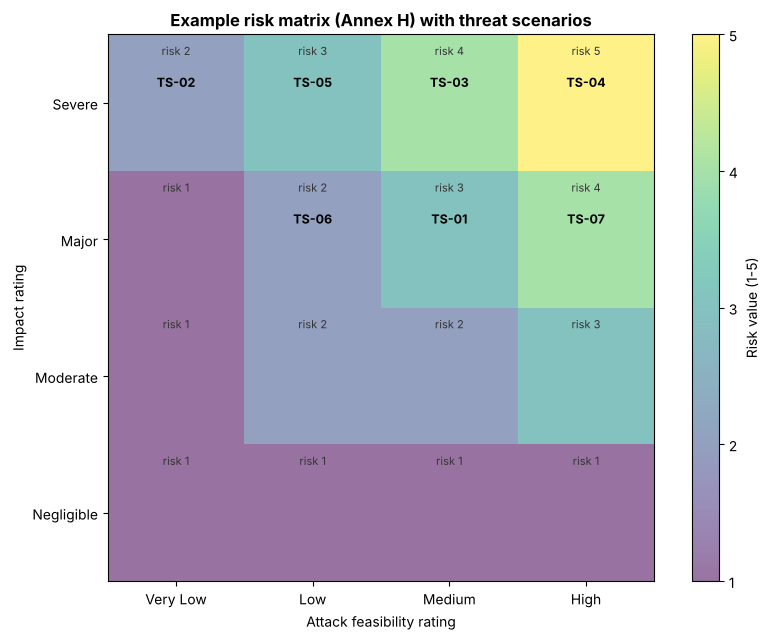

--- Risk values (text summary) ---
  TS-04: Severe x High -> risk 5
  TS-07: Major x High -> risk 4
  TS-03: Severe x Medium -> risk 4
  TS-05: Severe x Low -> risk 3
  TS-01: Major x Medium -> risk 3
  TS-02: Severe x Very Low -> risk 2
  TS-06: Major x Low -> risk 2


In [10]:
threats['Risk'] = [RISK_MATRIX[i][f] for i, f in zip(threats['Impact'], threats['Feasibility'])]
display(threats[['TS', 'Impact', 'Feasibility', 'Risk']])

def plot_risk_matrix(df, title, risk_col='Risk', impact_col='Impact', feas_col='Feasibility'):
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    matrix = np.array([[RISK_MATRIX[i][f] for f in FEASIBILITY_LEVELS] for i in IMPACT_LEVELS])
    im = ax.imshow(matrix, cmap='viridis', vmin=1, vmax=5, origin='lower', alpha=0.55)
    for i in range(4):
        for j in range(4):
            ax.text(j, i + 0.38, f'risk {matrix[i, j]}', ha='center', va='center', fontsize=8, color='0.2')
    placed = {}
    for r in df.itertuples():
        x, y = FEASIBILITY_LEVELS.index(getattr(r, feas_col)), IMPACT_LEVELS.index(getattr(r, impact_col))
        k = placed.get((x, y), 0); placed[(x, y)] = k + 1
        ax.text(x, y + 0.15 - 0.17 * k, r.TS, ha='center', va='center', fontsize=9, fontweight='bold')
    ax.set_xticks(range(4)); ax.set_xticklabels(FEASIBILITY_LEVELS)
    ax.set_yticks(range(4)); ax.set_yticklabels(IMPACT_LEVELS)
    ax.set_xlabel('Attack feasibility rating'); ax.set_ylabel('Impact rating')
    ax.set_title(title, fontweight='bold')
    fig.colorbar(im, ax=ax, label='Risk value (1-5)', ticks=[1, 2, 3, 4, 5])
    plt.tight_layout(); plt.show()

plot_risk_matrix(threats, 'Example risk matrix (Annex H) with threat scenarios')
print('--- Risk values (text summary) ---')
for r in threats.sort_values('Risk', ascending=False).itertuples():
    print(f'  {r.TS}: {r.Impact} x {r.Feasibility} -> risk {r.Risk}')

## 10. Step 7 — Risk treatment decision (15.9), goals, claims and CAL

The four options are **avoid** (remove the activity or function), **reduce** (controls), **share** (e.g. contracts, insurance) and **retain** (accept the risk).
Every threat scenario receives a decision with a rationale.

- **Reduce** → a **cybersecurity goal** (cl. 9.4), with a CAL assigned to the goal.
- **Share / retain** → a **cybersecurity claim** that documents the rationale.

The thresholds below are an *example organisation policy*. ISO/SAE 21434 leaves the acceptance criteria to the organisation, which must document them.

The CAL for each goal uses the Annex E example (impact × most remote attack vector). It scales the rigour of the assurance activities, e.g. the depth of testing and the independence of reviews. It is **not** a risk value, as the table below shows: TS-04 has risk 5 but receives a low CAL.

In [11]:
def treatment_decision(risk, safety_impact):
    """Example policy: reduce risk >= 3; reduce risk 2 if a Severe safety impact is possible; otherwise retain."""
    if risk >= 3:
        return 'Reduce', f'risk value {risk} >= 3'
    if risk == 2 and safety_impact == 'Severe':
        return 'Reduce', 'risk value 2 with Severe safety impact (policy)'
    return 'Retain', f'risk value {risk} within acceptance threshold; no Severe safety impact'

decisions = [treatment_decision(r, si) for r, si in zip(threats['Risk'], threats['Safety impact'])]
threats['Decision'] = [d[0] for d in decisions]
threats['Rationale'] = [d[1] for d in decisions]

def lc_first(text):
    return text[0].lower() + text[1:]

out = []
for r in threats.to_dict('records'):
    if r['Decision'] == 'Reduce':
        cal = determine_cal(r['Impact'], r['Most remote vector'])
        out.append({'ID': 'CG-' + r['TS'][3:], 'Type': 'Cybersecurity goal', 'TS': r['TS'],
                    'Statement': f"The {r['Property'].lower()} of the {lc_first(asset_name[r['Asset']])} shall be protected against {r['Cause']}.",
                    'CAL': f'CAL {cal}' if cal else 'none', 'Risk': r['Risk']})
    else:
        out.append({'ID': 'CC-' + r['TS'][3:], 'Type': 'Cybersecurity claim', 'TS': r['TS'],
                    'Statement': f"Risk retained ({r['Rationale']}); re-evaluated by cybersecurity monitoring (cl. 8).",
                    'CAL': 'n/a', 'Risk': r['Risk']})
goals = pd.DataFrame(out)
assert len(goals) == len(threats) and goals.TS.is_unique, 'every threat scenario needs exactly one treatment output'
display(threats[['TS', 'Risk', 'Safety impact', 'Decision', 'Rationale']])
display(goals)
print('--- Goals and claims (text summary) ---')
for g in goals.to_dict('records'):
    print(f"  {g['ID']} ({g['Type']}, {g['TS']}, risk {g['Risk']}, {g['CAL']}): {g['Statement']}")

,TS,Risk,Safety impact,Decision,Rationale
0,TS-01,3,Major,Reduce,risk value 3 >= 3
1,TS-02,2,Severe,Reduce,risk value 2 with Severe safety impact (policy)
2,TS-03,4,Severe,Reduce,risk value 4 >= 3
3,TS-04,5,Severe,Reduce,risk value 5 >= 3
4,TS-05,3,Severe,Reduce,risk value 3 >= 3
5,TS-06,2,Negligible,Retain,risk value 2 within acceptance threshold; no Severe safety impact
6,TS-07,4,Negligible,Reduce,risk value 4 >= 3


,ID,Type,TS,Statement,CAL,Risk
0,CG-01,Cybersecurity goal,TS-01,The integrity of the object list / brake request on CAN-FD shall be protecte...,CAL 4,3
1,CG-02,Cybersecurity goal,TS-02,The integrity of the perception DNN weights and configuration shall be prote...,CAL 4,2
2,CG-03,Cybersecurity goal,TS-03,The integrity of the object list / brake request on CAN-FD shall be protecte...,CAL 2,4
3,CG-04,Cybersecurity goal,TS-04,The availability of the camera video stream (camera -> perception ECU) shall...,CAL 2,5
4,CG-05,Cybersecurity goal,TS-05,The integrity of the camera calibration parameters (extrinsics) shall be pro...,CAL 3,3
5,CC-06,Cybersecurity claim,TS-06,Risk retained (risk value 2 within acceptance threshold; no Severe safety im...,n/a,2
6,CG-07,Cybersecurity goal,TS-07,The availability of the object list / brake request on CAN-FD shall be prote...,CAL 1,4


--- Goals and claims (text summary) ---
  CG-01 (Cybersecurity goal, TS-01, risk 3, CAL 4): The integrity of the object list / brake request on CAN-FD shall be protected against forged object-list/brake-request frames injected on CAN-FD.
  CG-02 (Cybersecurity goal, TS-02, risk 2, CAL 4): The integrity of the perception DNN weights and configuration shall be protected against manipulated DNN weights installed through a malicious software update.
  CG-03 (Cybersecurity goal, TS-03, risk 4, CAL 2): The integrity of the object list / brake request on CAN-FD shall be protected against a physical adversarial patch that suppresses pedestrian detections.
  CG-04 (Cybersecurity goal, TS-04, risk 5, CAL 2): The availability of the camera video stream (camera -> perception ECU) shall be protected against dazzling of the camera with a high-power light source.
  CG-05 (Cybersecurity goal, TS-05, risk 3, CAL 3): The integrity of the camera calibration parameters (extrinsics) shall be protected agai

### Controls and residual risk

Goals are refined into a cybersecurity concept (cl. 9.5): requirements that are allocated to architecture elements and then implemented as **controls**.
We model each control by the attack-potential factor values it forces on *every* path (a "floor"). For example, SecOC with keys in an HSM means that forging frames requires *strictly confidential* key material.
A control can also change the *damage scenario*: blinding detection with a degraded mode turns "missed pedestrian" (DS-02) into "AEB unavailable, driver warned" (DS-03).
We then re-run steps 5–6 to obtain the **residual risk**.

> **Illustrative data:** control effects are teaching assumptions; in practice they are argued and verified (cl. 10, 11).

,TS,Risk before,Impact after,Attack potential after,Feasibility after,Residual risk,Status
0,TS-01,3,Major,26,Very Low,1,acceptable
1,TS-02,2,Severe,41,Very Low,2,acceptable
2,TS-03,4,Severe,36,Very Low,2,acceptable
3,TS-04,5,Major,7,High,4,further treatment or documented acceptance needed
4,TS-05,3,Severe,29,Very Low,2,acceptable
5,TS-07,4,Major,17,Medium,3,further treatment or documented acceptance needed


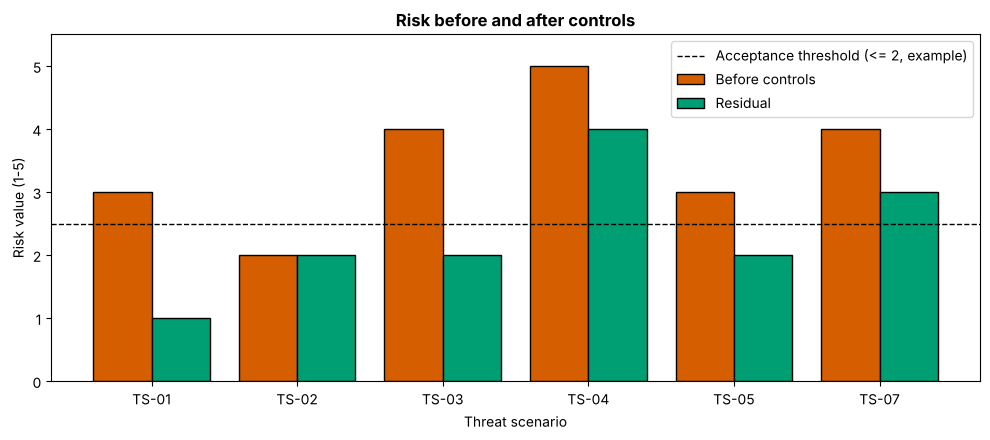

--- Residual risk (text summary) ---
  TS-01: risk 3 -> 1 (acceptable)
  TS-02: risk 2 -> 2 (acceptable)
  TS-03: risk 4 -> 2 (acceptable)
  TS-04: risk 5 -> 4 (further treatment or documented acceptance needed)
  TS-05: risk 3 -> 2 (acceptable)
  TS-07: risk 4 -> 3 (further treatment or documented acceptance needed)


In [12]:
controls = {
    'TS-01': {'controls': 'SecOC (AUTOSAR) with 128-bit CMAC truncated to 64 bit, freshness counter, keys in HSM; plausibility check in brake ECU',
              'floors': {'knowledge': 'strictly confidential', 'expertise': 'expert'}},
    'TS-02': {'controls': 'Signed packages verified before installation (ISO 24089 / UN R156 process), secure boot, signing keys in HSM',
              'floors': {}},
    'TS-03': {'controls': 'AEB intervention requires confirmation by the independent radar channel; perception plausibility monitor',
              'floors': {'elapsed_time': '<=6 months', 'expertise': 'multiple experts', 'equipment': 'bespoke'}},
    'TS-04': {'controls': 'Blinding/saturation detection with transition to degraded mode and driver warning',
              'damage': ['DS-03']},
    'TS-05': {'controls': 'UDS Authentication 0x29 (ISO 14229-1:2020, certificate-based, role-based write access) replaces seed/key 0x27',
              'floors': {'knowledge': 'strictly confidential'}},
    'TS-07': {'controls': 'AEB messages on a dedicated segment, not reachable from bumper-mounted connectors; bus-load monitoring',
              'floors': {'window': 'difficult'}},
}
ACCEPTABLE_RESIDUAL = 2   # example organisation policy

res = []
for r in threats[threats.Decision == 'Reduce'].to_dict('records'):
    c = controls[r['TS']]
    ds = c.get('damage', r['Damage scenarios'])
    impact = impact_of(ds)[0]
    _, agg, _ = rate_feasibility(r['TS'], c.get('floors'))
    risk = RISK_MATRIX[impact][agg['feasibility']]
    res.append({'TS': r['TS'], 'Controls': c['controls'], 'Risk before': r['Risk'],
                'Impact after': impact, 'Feasibility after': agg['feasibility'],
                'Attack potential after': agg['attack_potential'], 'Residual risk': risk,
                'Status': 'acceptable' if risk <= ACCEPTABLE_RESIDUAL else 'further treatment or documented acceptance needed'})
residual = pd.DataFrame(res)
display(residual[['TS', 'Risk before', 'Impact after', 'Attack potential after', 'Feasibility after', 'Residual risk', 'Status']])

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(residual))
ax.bar(x - 0.2, residual['Risk before'], 0.4, label='Before controls', color=OKABE_ITO[5], edgecolor='black')
ax.bar(x + 0.2, residual['Residual risk'], 0.4, label='Residual', color=OKABE_ITO[2], edgecolor='black')
ax.axhline(ACCEPTABLE_RESIDUAL + 0.5, ls='--', color='black', lw=1, label=f'Acceptance threshold (<= {ACCEPTABLE_RESIDUAL}, example)')
ax.set_xticks(x); ax.set_xticklabels(residual.TS)
ax.set_xlabel('Threat scenario'); ax.set_ylabel('Risk value (1-5)'); ax.set_ylim(0, 5.5)
ax.set_title('Risk before and after controls', fontweight='bold'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
print('--- Residual risk (text summary) ---')
for r in residual.to_dict('records'):
    print(f"  {r['TS']}: risk {r['Risk before']} -> {r['Residual risk']} ({r['Status']})")

**Interpreting the residual risk.** Controls that raise the cost of an attack work well against bus forgery (TS-01) and diagnostic abuse (TS-05).
**Physical sensor attacks behave differently.** No vehicle-side control prevents someone from shining a light into a camera (TS-04). The best achievable outcome is to *detect and degrade safely*. That lowers the safety impact, but an operational impact remains. Such residual risks are typically accepted with a documented claim, or reduced further by architecture (sensor diversity) and monitored in the field (cl. 8).

## 11. End-to-end traceability

The table below is generated from the analysis above; nothing is typed in by hand. It is the TARA view a reviewer or assessor
(ISO/SAE PAS 5112) would follow: safety goal → damage scenario → threat scenario → attack path → feasibility → risk → treatment → goal/claim, CAL → residual risk.

In [13]:
trace = []
goal_by_ts = goals.set_index('TS')
resid_by_ts = residual.set_index('TS')['Residual risk']
for r in threats.to_dict('records'):
    g = goal_by_ts.loc[r['TS']]
    resid = int(resid_by_ts.get(r['TS'], r['Risk']))
    for ds in r['Damage scenarios']:
        trace.append({'SG': ds_index.loc[ds, 'Safety goal'], 'DS': ds, 'TS': r['TS'],
                      'Asset/property': f"{r['Asset']}/{r['Property']}", 'Path': r['Most feasible path'],
                      'AP': r['Attack potential'], 'Feasibility': r['Feasibility'], 'Impact': r['Impact'],
                      'Risk': r['Risk'], 'Decision': r['Decision'], 'Goal/claim': g['ID'], 'CAL': g['CAL'], 'Residual': resid})
trace = pd.DataFrame(trace).sort_values(['SG', 'DS', 'TS'])
display(trace)
assert trace.TS.nunique() == len(threats)
print('--- Traceability (text summary) ---')
for r in trace.to_dict('records'):
    print(f"  {r['SG']} <- {r['DS']} <- {r['TS']} ({r['Asset/property']}) via {r['Path']} [AP {r['AP']}, {r['Feasibility']}] "
          f"-> risk {r['Risk']} -> {r['Decision']} -> {r['Goal/claim']} ({r['CAL']}) -> residual {r['Residual']}")

,SG,DS,TS,Asset/property,Path,AP,Feasibility,Impact,Risk,Decision,Goal/claim,CAL,Residual
4,-,DS-03,TS-04,A-01/Availability,AP-04a,7,High,Severe,5,Reduce,CG-04,CAL 2,4
7,-,DS-03,TS-07,A-03/Availability,AP-07a,11,High,Major,4,Reduce,CG-07,CAL 1,3
6,-,DS-04,TS-06,A-06/Confidentiality,AP-06a,21,Low,Major,2,Retain,CC-06,n/a,2
0,SG-01,DS-01,TS-01,A-03/Integrity,AP-01b,15,Medium,Major,3,Reduce,CG-01,CAL 4,1
1,SG-02,DS-02,TS-02,A-02/Integrity,AP-02b,41,Very Low,Severe,2,Reduce,CG-02,CAL 4,2
2,SG-02,DS-02,TS-03,A-03/Integrity,AP-03a,14,Medium,Severe,4,Reduce,CG-03,CAL 2,2
3,SG-02,DS-02,TS-04,A-01/Availability,AP-04a,7,High,Severe,5,Reduce,CG-04,CAL 2,4
5,SG-02,DS-02,TS-05,A-05/Integrity,AP-05a,21,Low,Severe,3,Reduce,CG-05,CAL 3,2


--- Traceability (text summary) ---
  - <- DS-03 <- TS-04 (A-01/Availability) via AP-04a [AP 7, High] -> risk 5 -> Reduce -> CG-04 (CAL 2) -> residual 4
  - <- DS-03 <- TS-07 (A-03/Availability) via AP-07a [AP 11, High] -> risk 4 -> Reduce -> CG-07 (CAL 1) -> residual 3
  - <- DS-04 <- TS-06 (A-06/Confidentiality) via AP-06a [AP 21, Low] -> risk 2 -> Retain -> CC-06 (n/a) -> residual 2
  SG-01 <- DS-01 <- TS-01 (A-03/Integrity) via AP-01b [AP 15, Medium] -> risk 3 -> Reduce -> CG-01 (CAL 4) -> residual 1
  SG-02 <- DS-02 <- TS-02 (A-02/Integrity) via AP-02b [AP 41, Very Low] -> risk 2 -> Reduce -> CG-02 (CAL 4) -> residual 2
  SG-02 <- DS-02 <- TS-03 (A-03/Integrity) via AP-03a [AP 14, Medium] -> risk 4 -> Reduce -> CG-03 (CAL 2) -> residual 2
  SG-02 <- DS-02 <- TS-04 (A-01/Availability) via AP-04a [AP 7, High] -> risk 5 -> Reduce -> CG-04 (CAL 2) -> residual 4
  SG-02 <- DS-02 <- TS-05 (A-05/Integrity) via AP-05a [AP 21, Low] -> risk 3 -> Reduce -> CG-05 (CAL 3) -> residual 2


## 12. Safety–security co-engineering

ISO 26262 and ISO/SAE 21434 remain separate disciplines with separate work products, but they must exchange information.
ISO 26262-2:2018 asks for communication channels between functional safety and cybersecurity, and its informative Annex E describes typical interactions.
ISO/SAE 21434 clause 5 asks for the same at the organisational level.

1. **Shared item definition.** One item definition, one boundary, one set of operating modes. In this notebook both analyses refer to the same AEB item.
2. **Safety goals as damage scenarios.** Every TARA damage scenario that violates a safety goal is linked to it. The threat scenarios reaching those damage scenarios are **cybersecurity events with potential safety impact**, and they must be communicated to the safety team.
3. **Controls versus safety mechanisms.** A security control that is credited in the safety argument (e.g. a plausibility check that also rejects forged brake requests) must meet the safety requirements for its timing, ASIL and independence. The reverse also holds: safety mechanisms such as E2E protection with CRC and counters detect *random* corruption, but they do **not** stop an attacker who can recompute the CRC.
4. **Timing.** Detection and reaction by a security control must fit within the safety goal's **FTTI** if the control is part of keeping the vehicle safe. Cryptographic checks can also *cause* frame loss, e.g. after a loss of freshness synchronisation. That frame loss must be covered by the safety concept.
5. **No label arithmetic.** ASIL and CAL are derived independently and do not map onto each other. A requirement can carry both an ASIL and a CAL, but "ASIL D + CAL 3" is not a requirement in itself.

In [14]:
# (a) Cybersecurity events with potential safety impact, derived from the traceability table
safety_relevant = trace[trace.SG != '-'].groupby('SG').agg(
    threat_scenarios=('TS', lambda s: ', '.join(sorted(set(s)))),
    max_risk=('Risk', 'max'), max_residual=('Residual', 'max')).reset_index()
safety_relevant = safety_relevant.merge(safety_goals[['SG', 'Safety goal', 'ASIL', 'FTTI_ms']], on='SG')
display(safety_relevant)
for r in safety_relevant.to_dict('records'):
    print(f"{r['SG']} (ASIL {r['ASIL']}) can be violated by: {r['threat_scenarios']} "
          f"(max risk {r['max_risk']}, max residual {r['max_residual']}) -> communicate to the safety team")

# (b) Timing of security controls against the FTTI (illustrative values)
CAN_PERIOD_MS, CAMERA_PERIOD_MS = 20, 33
timing = pd.DataFrame([
    ('SecOC rejects a forged brake request', 'SG-01', 0.1, 0.0, True),
    ('Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> degraded', 'SG-02', 3 * CAN_PERIOD_MS, 50.0, True),
    ('On-board timing IDS needs 5 anomalous frames, then ignores the sender', 'SG-01', 5 * CAN_PERIOD_MS, 50.0, False),
    ('Camera blinding detection (3 frames) -> degraded mode', 'SG-02', 3 * CAMERA_PERIOD_MS, 50.0, True),
    ('Backend VSOC detects attack, pushes countermeasure', 'SG-01', 3600e3, 0.0, False),
], columns=['Control', 'SG', 'Detection_ms', 'Reaction_ms', 'Acts before first malicious effect'])
timing = timing.merge(safety_goals[['SG', 'FTTI_ms']], on='SG')
timing['Total_ms'] = timing.Detection_ms + timing.Reaction_ms
timing['Within FTTI'] = timing.Total_ms <= timing.FTTI_ms
timing['Usable as safety mechanism'] = timing['Within FTTI'] & timing['Acts before first malicious effect']
display(timing)
print('--- Timing check (text summary) ---')
for r in timing.to_dict('records'):
    print(f"  {r['Control']}: {r['Total_ms']:.1f} ms vs FTTI {r['FTTI_ms']} ms ({r['SG']}) -> "
          f"{'within' if r['Within FTTI'] else 'exceeds'} FTTI; usable as safety mechanism: {r['Usable as safety mechanism']}")

,SG,threat_scenarios,max_risk,max_residual,Safety goal,ASIL,FTTI_ms
0,SG-01,TS-01,3,1,Avoid unintended emergency braking,B,200
1,SG-02,"TS-02, TS-03, TS-04, TS-05",5,4,Avoid omission of emergency braking for a pedestrian in the path,C,300


SG-01 (ASIL B) can be violated by: TS-01 (max risk 3, max residual 1) -> communicate to the safety team
SG-02 (ASIL C) can be violated by: TS-02, TS-03, TS-04, TS-05 (max risk 5, max residual 4) -> communicate to the safety team


,Control,SG,Detection_ms,Reaction_ms,Acts before first malicious effect,FTTI_ms,Total_ms,Within FTTI,Usable as safety mechanism
0,SecOC rejects a forged brake request,SG-01,0.1,0.0,True,200,0.1,True,True
1,Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> de...,SG-02,60.0,50.0,True,300,110.0,True,True
2,"On-board timing IDS needs 5 anomalous frames, then ignores the sender",SG-01,100.0,50.0,False,200,150.0,True,False
3,Camera blinding detection (3 frames) -> degraded mode,SG-02,99.0,50.0,True,300,149.0,True,True
4,"Backend VSOC detects attack, pushes countermeasure",SG-01,3600000.0,0.0,False,200,3600000.0,False,False


--- Timing check (text summary) ---
  SecOC rejects a forged brake request: 0.1 ms vs FTTI 200 ms (SG-01) -> within FTTI; usable as safety mechanism: True
  Freshness loss -> valid frames dropped -> brake-ECU timeout (3 frames) -> degraded: 110.0 ms vs FTTI 300 ms (SG-02) -> within FTTI; usable as safety mechanism: True
  On-board timing IDS needs 5 anomalous frames, then ignores the sender: 150.0 ms vs FTTI 200 ms (SG-01) -> within FTTI; usable as safety mechanism: False
  Camera blinding detection (3 frames) -> degraded mode: 149.0 ms vs FTTI 300 ms (SG-02) -> within FTTI; usable as safety mechanism: True
  Backend VSOC detects attack, pushes countermeasure: 3600000.0 ms vs FTTI 200 ms (SG-01) -> exceeds FTTI; usable as safety mechanism: False


**Reading the timing check.** The backend VSOC is essential for fleet-level response (cl. 8, 13), but it works on a timescale of hours. It is not a safety mechanism.
An on-board IDS that alerts only after several frames lets the first forged frames through. It may fit the FTTI, but it does not prevent the hazardous event on its own. It needs a preventive partner such as SecOC or a plausibility check.
Notebook 4 builds such an IDS: [CAN bus intrusion detection](04_can_bus_intrusion_detection.ipynb).

## 13. Exercise: perform your own TARA for V2X

Perform a TARA for a V2X receiver that feeds cooperative perception objects (e.g. ETSI CPM/DENM) into the same AEB function.
Use the helpers above. One threat is pre-filled. Add at least three more, for example:
1. GNSS spoofing that corrupts the ego position used to match V2X objects;
2. replay of an old, validly signed hazard warning;
3. a misbehaving insider device with a valid pseudonym certificate (Sybil attack);
4. radio-channel jamming (availability).

Hints: V2X messages are **signed, not encrypted** (IEEE 1609.2 / ETSI TS 103 097). The PKI is the SCMS in the US and the EU C-ITS CCMS (ETSI TS 102 940/941) in Europe. Background: [V2X cooperative driving](../07_Runtime_Assurance_and_Operations/02_v2x_cooperative_driving.ipynb).

In [15]:
# Exercise scaffold: extend the lists, then re-run.
v2x_paths = {
    'TS-V01': {'AP-V01a': [step('Extract a pseudonym certificate key from a purchased aftermarket OBU', '<=6 months', 'expert', 'restricted', 'unlimited', 'specialized', 'Physical'),
                           step('Broadcast a forged "pedestrian on road" message within radio range', '<=1 day', 'proficient', 'public', 'easy', 'specialized')],
               'AP-V01b': [step('Spoof a message without a valid certificate (rejected by signature check)', '<=6 months', 'multiple experts', 'strictly confidential', 'easy', 'bespoke', 'Adjacent')]},
    # 'TS-V02': {...},  # TODO: your threat scenarios
}
v2x_impact = {'TS-V01': 'Major'}   # DS: unintended emergency braking (cf. DS-01); TODO: rate your own

for ts, paths in v2x_paths.items():
    aggs = {ap: aggregate_and(s) for ap, s in paths.items()}
    best = min(aggs, key=lambda k: aggs[k]['attack_potential'])
    remote = max((a['vector'] for a in aggs.values()), key=VECTORS.index)
    f = aggs[best]['feasibility']
    print(f"{ts}: best path {best} (AP {aggs[best]['attack_potential']}, {f}), impact {v2x_impact[ts]}, "
          f"risk {RISK_MATRIX[v2x_impact[ts]][f]}, CAL if reduced: {determine_cal(v2x_impact[ts], remote)} ({remote})")

TS-V01: best path AP-V01a (AP 31, Very Low), impact Major, risk 1, CAL if reduced: 3 (Adjacent)


## Key takeaways

1. **Seven steps, fixed order:** assets & damage scenarios → threat scenarios → impact → attack paths → feasibility → risk value → treatment.
2. **Threat scenario = asset + property + cause**, linked to damage scenarios that are rated for the road user.
3. **Attack paths make feasibility reviewable.** Choose an aggregation convention (here: AND = factor-wise maximum, OR = most feasible path) and document it.
4. **Attack potential 0–13 is High feasibility.** The risk value comes from the example matrix (1–5).
5. **Every threat scenario gets a treatment decision.** Reduce leads to a cybersecurity goal with a CAL; retain or share leads to a cybersecurity claim.
6. **CAL** follows from impact and attack vector (Annex E, informative). It is neither a risk value nor an ASIL.
7. **Residual risk** shows which controls actually work. Physical sensor attacks can usually only be detected and degraded, not prevented.
8. **Co-engineering:** share the item definition, link damage scenarios to safety goals, and check the timing of security controls against the FTTI.

## Self-assessment

1. List the seven TARA steps with their sub-clause numbers.
2. Why must a threat scenario name the cybersecurity property, not just the asset?
3. A path has steps with (elapsed, expertise, knowledge, window, equipment) = (1, 3, 3, 4, 4) and (1, 3, 3, 0, 0). What is the aggregated attack potential and the feasibility under the convention used here?
4. Why can TS-04 (camera dazzling) have risk 5 but only CAL 2?
5. What is the difference between a cybersecurity goal and a cybersecurity claim?
6. Why is a backend VSOC not a safety mechanism for SG-01?
7. Does E2E protection (CRC + alive counter) protect against forged frames? Why or why not?

<details>
<summary>Answers</summary>

1. 15.3 assets & damage scenarios, 15.4 threat scenarios, 15.5 impact rating, 15.6 attack path analysis, 15.7 attack feasibility rating, 15.8 risk value determination, 15.9 risk treatment decision.
2. The property determines both the damage and the controls. A loss of *integrity* of the object list calls for authentication or cross-checks; a loss of *availability* calls for detection and degradation.
3. Factor-wise maximum (1, 3, 3, 4, 4) → 15 → **Medium**.
4. The risk combines Severe impact with High feasibility. The CAL example uses impact × attack vector, and a Physical vector with Severe impact gives CAL 2.
5. A goal is a requirement to protect an asset against a threat scenario (risk *reduced*). A claim documents why a retained or shared risk is acceptable.
6. Its detection-plus-reaction time (hours) is far beyond the FTTI (milliseconds), and it acts only after the hazardous event.
7. No. CRC and counters are not secret, so an attacker can compute valid values. Only a keyed MAC (e.g. SecOC) gives authenticity.
</details>

## References

- ISO/SAE 21434:2021, *Road vehicles — Cybersecurity engineering*, clauses 9 and 15, Annexes E, F, G, H.
- ISO 26262-3:2018, *Road vehicles — Functional safety — Part 3: Concept phase* (Table 4).
- ISO 26262-2:2018, *Part 2: Management of functional safety* (Annex E, interaction with cybersecurity).
- ISO/IEC 18045:2022, *Methodology for IT security evaluation* (attack-potential factors).
- ISO 14229-1:2020, *Unified diagnostic services (UDS) — Part 1* (Authentication service 0x29).
- AUTOSAR, *Specification of Secure Onboard Communication* (SWS SecOC), Classic Platform R22-11 or later. https://www.autosar.org
- Shostack, A. (2014). *Threat Modeling: Designing for Security*. Wiley (STRIDE).
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components. LNCS (Springer). https://doi.org/10.1007/978-3-032-35506-5_55

## Further practice

- Companion workshop exercise: [TARA exercise](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/10_tara_exercise.ipynb) (AI Perception Safety Workshop).
- Professional template consistent with this notebook: [TARA template](../templates/TARA_Template.md).

---
**Navigation:** ← [ISO/SAE 21434 fundamentals](01_iso21434_fundamentals.ipynb) · [Module index](README.md) · [Attack surface analysis](03_attack_surface_analysis.ipynb) →